# Analysis Results Summary

Summary of metrics across all experimental runs

In [1]:
import pandas as pd
import numpy as np
import json
import re
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (15, 10)

## Load All Metrics

In [2]:
# Find all analysis_metrics.json files
root_dir = Path.cwd().parent  # Go up one level from eval/ to synthetic_optim/
metric_files = sorted(root_dir.glob('nnodes*/seed8*/analysis_metrics.json'))

print(f"Found {len(metric_files)} metric files")

# Load all metrics
all_metrics = []

for metric_file in metric_files:
    with open(metric_file, 'r') as f:
        metrics = json.load(f)
    
    # Parse path to extract parameters
    parent_dir = metric_file.parent.parent.name
    seed_dir = metric_file.parent.name
    
    # Extract parameters from directory name
    nnodes_match = re.search(r'nnodes(\d+)', parent_dir)
    prob_match = re.search(r'prob([\d.]+)', parent_dir)
    noise_match = re.search(r'noise([\d.]+)', parent_dir)
    ntargets_match = re.search(r'ntargets(\d+)', parent_dir)
    seed_match = re.search(r'seed(\d+)', seed_dir)
    
    metrics['nnodes'] = int(nnodes_match.group(1)) if nnodes_match else None
    metrics['prob'] = float(prob_match.group(1)) if prob_match else None
    metrics['noise'] = float(noise_match.group(1)) if noise_match else None
    metrics['ntargets'] = int(ntargets_match.group(1)) if ntargets_match else None
    metrics['seed'] = int(seed_match.group(1)) if seed_match else None
    metrics['path'] = str(metric_file.parent.relative_to(root_dir))
    
    all_metrics.append(metrics)

print(f"Loaded metrics from {len(all_metrics)} runs")

Found 270 metric files
Loaded metrics from 270 runs


## Aggregate Metrics Across Seeds

Calculate mean and standard deviation for each parameter combination

Note the std in aggregated_metrics.csv is divided by N-1, while the std in aggregated_metrics_summary.csv (here) is divided by N.

In [3]:
# Convert to DataFrame
all_metrics_df = pd.DataFrame(all_metrics)

# Metrics to aggregate
metrics_to_aggregate = [
    'recall_at_k',
    'best_solution_transprop',
    #'error_per_true_target',
    'de_recall_at_k',
    'de_best_transprop',
    'auc_our_solutions',
    'auc_de_solutions',
    'avg_transprop_our',
    'avg_transprop_de'
]

print(f"Loaded {len(all_metrics_df)} individual experiment results")
print(f"\nParameter combinations:")
print(f"  nnodes: {sorted(all_metrics_df['nnodes'].unique())}")
print(f"  prob: {sorted(all_metrics_df['prob'].unique())}")
print(f"  noise: {sorted(all_metrics_df['noise'].unique())}")
print(f"  ntargets: {sorted(all_metrics_df['ntargets'].unique())}")

# Keep individual seed values in all_metrics_df for later visualization
# Group by parameter combinations (excluding seed) for aggregation
grouping_cols = ['nnodes', 'prob', 'noise', 'ntargets']

# Calculate mean and std for each metric
aggregated_data = []

for params, group in all_metrics_df.groupby(grouping_cols):
    agg_dict = {
        'nnodes': params[0],
        'prob': params[1],
        'noise': params[2],
        'ntargets': params[3],
        'num_seeds': len(group)
    }
    
    for metric in metrics_to_aggregate:
        agg_dict[f'{metric}_mean'] = group[metric].mean()
        # If only one seed, std should be 0.0
        agg_dict[f'{metric}_std'] = group[metric].std() if len(group) > 1 else 0.0
        # Store individual seed values as a list for bar plots
        agg_dict[f'{metric}_values'] = group[metric].tolist()
    
    aggregated_data.append(agg_dict)

# Convert to DataFrame
aggregated_df = pd.DataFrame(aggregated_data)

print(f"\nAggregated {len(aggregated_df)} parameter combinations")
print(f"Individual seed values are kept in all_metrics_df and as lists in aggregated_df")
print(f"\nSample of aggregated data:")
print(aggregated_df.head(10))

# Save aggregated metrics to CSV
aggregated_df.to_csv('aggregated_metrics_summary.csv', index=False)
print("\n✓ Aggregated metrics saved to aggregated_metrics_summary.csv")

Loaded 270 individual experiment results

Parameter combinations:
  nnodes: [10, 100, 500]
  prob: [0.2, 0.5]
  noise: [1.0, 3.0, 5.0]
  ntargets: [1, 5, 10]

Aggregated 54 parameter combinations
Individual seed values are kept in all_metrics_df and as lists in aggregated_df

Sample of aggregated data:
   nnodes  prob  noise  ntargets  num_seeds  recall_at_k_mean  \
0      10   0.2    1.0         1          5              1.00   
1      10   0.2    1.0         5          5              1.00   
2      10   0.2    1.0        10          5              1.00   
3      10   0.2    3.0         1          5              1.00   
4      10   0.2    3.0         5          5              0.96   
5      10   0.2    3.0        10          5              1.00   
6      10   0.2    5.0         1          5              1.00   
7      10   0.2    5.0         5          5              0.96   
8      10   0.2    5.0        10          5              1.00   
9      10   0.5    1.0         1          5   

## Compare Recall@k vs DE Recall@k (nnodes=100, prob=0.2)

Visualizations comparing our method with differential expression baseline

### Visualization 1: Grouped by Noise Level (3 Subplots)

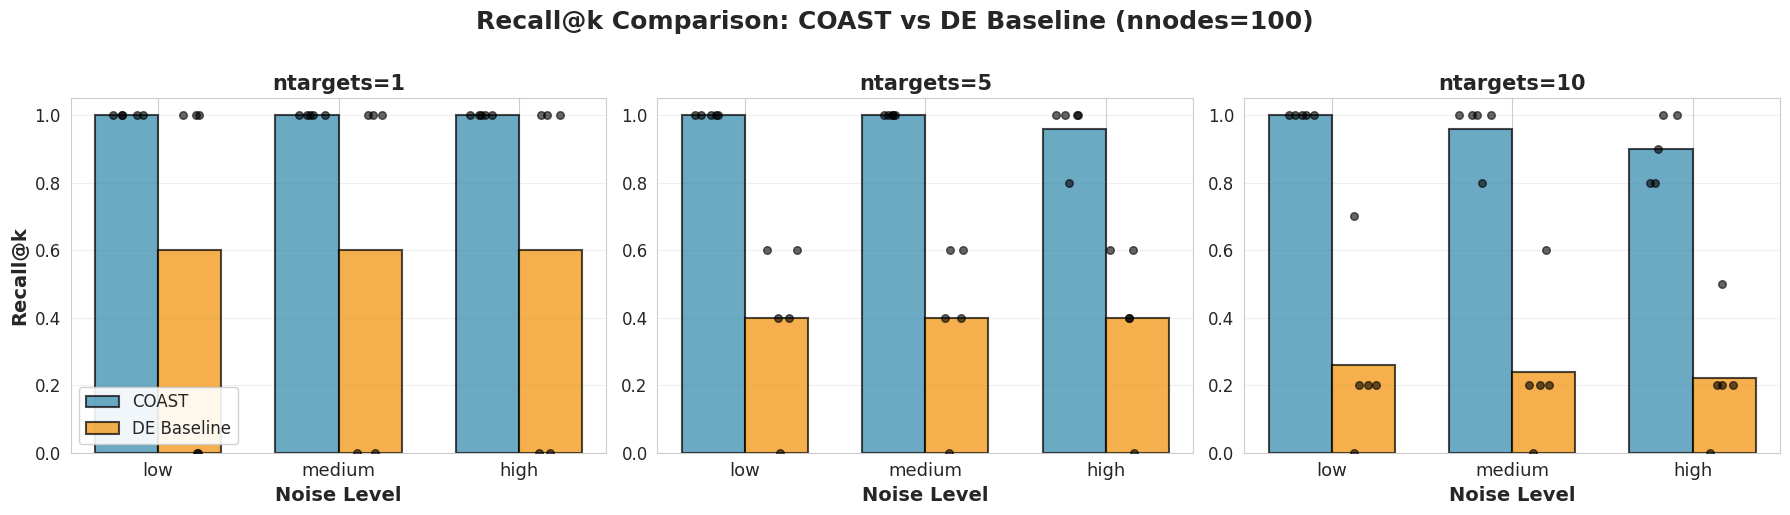


✓ Visualization 1b completed


In [6]:
# Create 3 subplots, one for each ntargets value
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Recall@k Comparison: COAST vs DE Baseline (nnodes=100)', 
            fontsize=18, fontweight='bold', y=1.02)

# Bar width and colors
bar_width = 0.35
method_colors = {'recall_at_k': '#2E86AB', 'de_recall_at_k': '#F18F01'}
method_labels = {'recall_at_k': 'COAST', 'de_recall_at_k': 'DE Baseline'}

for idx, ntargets in enumerate(ntargets_vals):
    ax = axes[idx]
    
    # Get x positions
    x_positions = np.arange(len(noise_vals))
    
    # Plot bars for each method
    bar_offset = -bar_width / 2
    for metric in ['recall_at_k', 'de_recall_at_k']:
        positions = x_positions + bar_offset
        
        # Collect data for each noise level
        data_to_plot = []
        for noise in noise_vals:
            subset = filtered_df[(filtered_df['ntargets'] == ntargets) & 
                                (filtered_df['noise'] == noise)]
            values = subset[metric].values
            data_to_plot.append(values)
        
        # Calculate means for bar heights
        means = [np.mean(vals) if len(vals) > 0 else 0 for vals in data_to_plot]
        
        # Plot bars with individual seed points
        bars = ax.bar(positions, means, bar_width,
                     label=method_labels[metric] if idx == 0 else None,
                     color=method_colors[metric],
                     alpha=0.7,
                     edgecolor='black', linewidth=1.5)
        
        # Add individual seed points
        for i, (pos, vals) in enumerate(zip(positions, data_to_plot)):
            if len(vals) > 0:
                # Add jitter to x-position for visibility
                jitter = np.random.normal(0, bar_width * 0.15, len(vals))
                ax.scatter(pos + jitter, vals, color='black', s=30, alpha=0.6, zorder=3)
        
        bar_offset += bar_width
    
    # Customize subplot
    ax.set_xlabel('Noise Level', fontsize=14, fontweight='bold')
    if idx == 0:
        ax.set_ylabel('Recall@k', fontsize=14, fontweight='bold')
    ax.set_title(f'ntargets={ntargets}', fontsize=15, fontweight='bold')
    ax.set_xticks(x_positions)
    ax.set_xticklabels(['low', 'medium', 'high'], fontsize=13)
    ax.set_ylim(0, 1.05)
    if idx == 0:
        ax.legend(loc='best', fontsize=12, framealpha=0.9)
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.savefig('recall_comparison_by_noise.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Visualization 1b completed")

## Compare TransProp vs DE TransProp (nnodes=100, prob=0.2)

Visualizations comparing our method with differential expression baseline

### Visualization 2

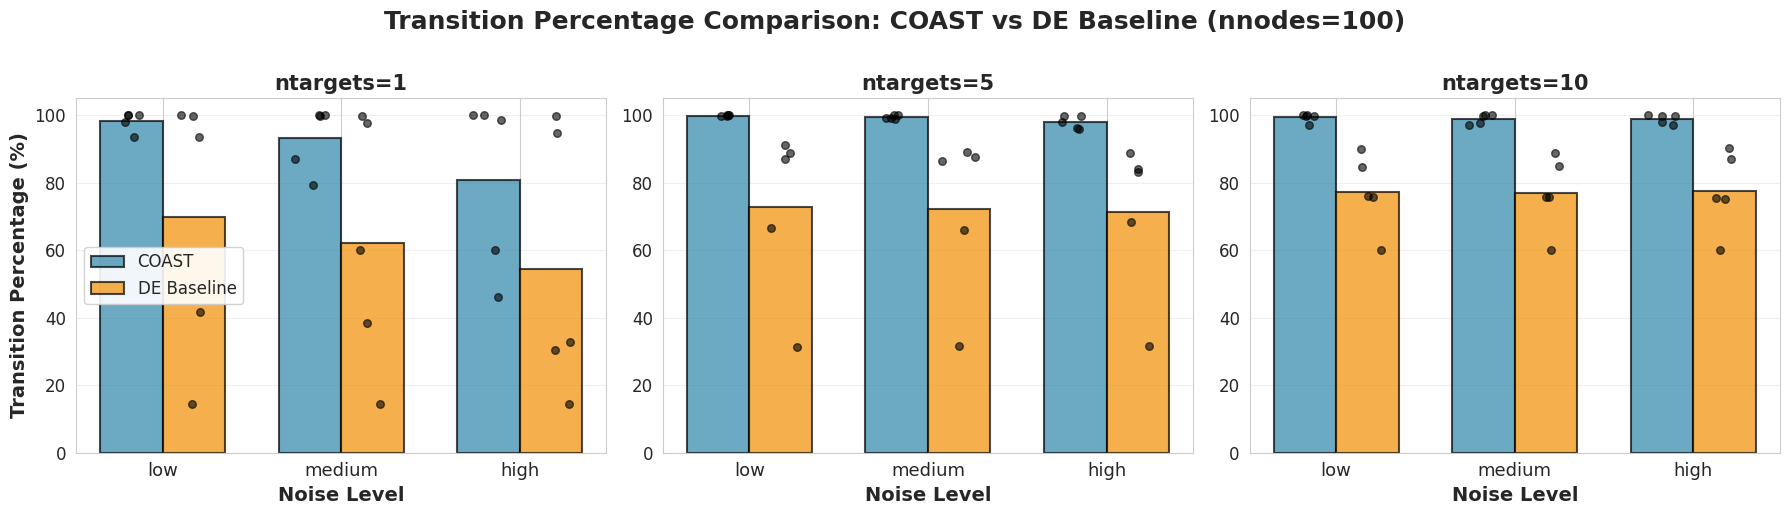


✓ Visualization 2b completed


In [9]:
# Create 3 subplots, one for each ntargets value
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Transition Percentage Comparison: COAST vs DE Baseline (nnodes=100)', 
            fontsize=18, fontweight='bold', y=1.02)

# Bar width and colors
bar_width = 0.35
method_colors = {'best_solution_transprop': '#2E86AB', 'de_best_transprop': '#F18F01'}
method_labels = {'best_solution_transprop': 'COAST', 'de_best_transprop': 'DE Baseline'}

for idx, ntargets in enumerate(ntargets_vals):
    ax = axes[idx]
    
    # Get x positions
    x_positions = np.arange(len(noise_vals))
    
    # Plot bars for each method
    bar_offset = -bar_width / 2
    for metric in ['best_solution_transprop', 'de_best_transprop']:
        positions = x_positions + bar_offset
        
        # Collect data for each noise level
        data_to_plot = []
        for noise in noise_vals:
            subset = filtered_df[(filtered_df['ntargets'] == ntargets) & 
                                (filtered_df['noise'] == noise)]
            values = subset[metric].values * 100  # Convert to percentage
            data_to_plot.append(values)
        
        # Calculate means for bar heights
        means = [np.mean(vals) if len(vals) > 0 else 0 for vals in data_to_plot]
        
        # Plot bars with individual seed points
        bars = ax.bar(positions, means, bar_width,
                     label=method_labels[metric] if idx == 0 else None,
                     color=method_colors[metric],
                     alpha=0.7,
                     edgecolor='black', linewidth=1.5)
        
        # Add individual seed points
        for i, (pos, vals) in enumerate(zip(positions, data_to_plot)):
            if len(vals) > 0:
                # Add jitter to x-position for visibility
                jitter = np.random.normal(0, bar_width * 0.15, len(vals))
                ax.scatter(pos + jitter, vals, color='black', s=30, alpha=0.6, zorder=3)
        
        bar_offset += bar_width
    
    # Customize subplot
    ax.set_xlabel('Noise Level', fontsize=14, fontweight='bold')
    if idx == 0:
        ax.set_ylabel('Transition Percentage (%)', fontsize=14, fontweight='bold')
    ax.set_title(f'ntargets={ntargets}', fontsize=15, fontweight='bold')
    ax.set_xticks(x_positions)
    ax.set_xticklabels(['low', 'medium', 'high'], fontsize=13)
    ax.set_ylim(0, 105)
    ax.set_yticks(np.arange(0, 101, 20))
    if idx == 0:
        ax.legend(loc='best', fontsize=12, framealpha=0.9)
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.savefig('transprop_comparison_by_noise.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Visualization 2b completed")

## Compare Avg TransProp: Our Method vs DE (nnodes=100, prob=0.2)

Average TransProp across all # of intervention targets (excluding 0)

### Visualization 3

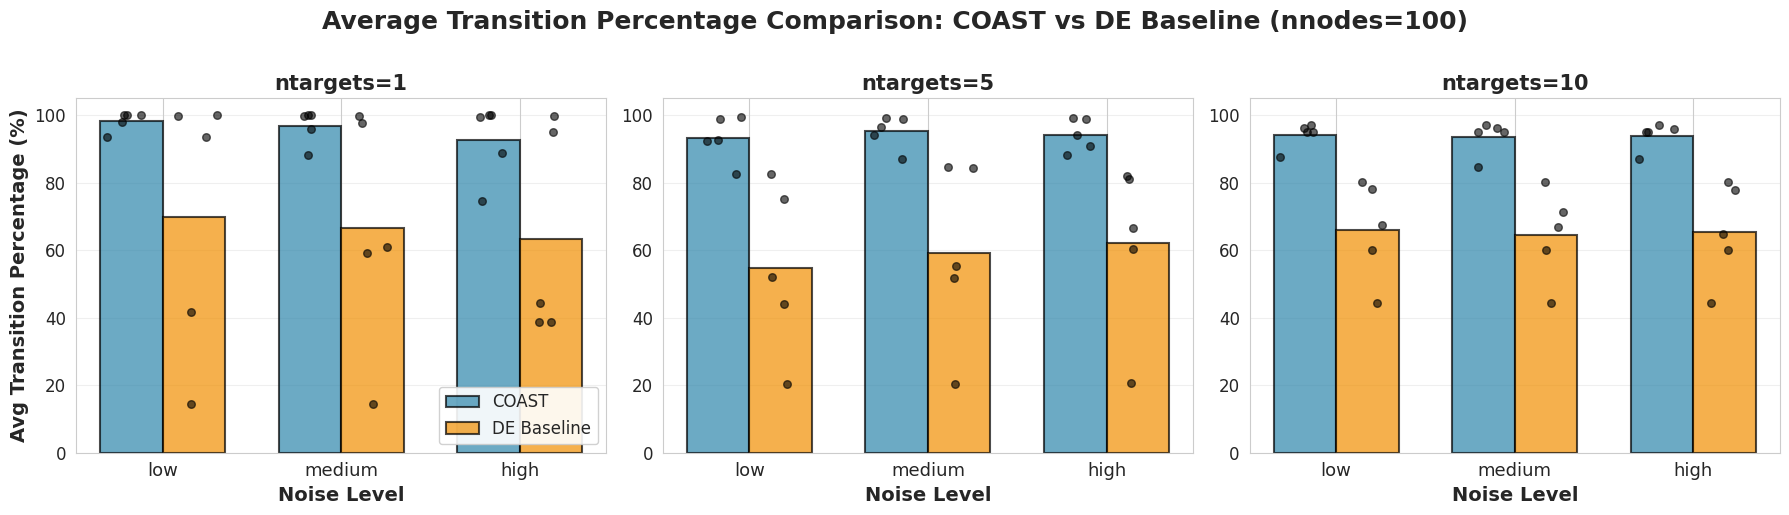


✓ Visualization 4b completed


In [15]:
# Create 3 subplots, one for each ntargets value
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Average Transition Percentage Comparison: COAST vs DE Baseline (nnodes=100)', 
            fontsize=18, fontweight='bold', y=1.02)

# Bar width and colors
bar_width = 0.35
method_colors = {'avg_transprop_our': '#2E86AB', 'avg_transprop_de': '#F18F01'}
method_labels = {'avg_transprop_our': 'COAST', 'avg_transprop_de': 'DE Baseline'}

for idx, ntargets in enumerate(ntargets_vals):
    ax = axes[idx]
    
    # Get x positions
    x_positions = np.arange(len(noise_vals))
    
    # Plot bars for each method
    bar_offset = -bar_width / 2
    for metric in ['avg_transprop_our', 'avg_transprop_de']:
        positions = x_positions + bar_offset
        
        # Collect data for each noise level
        data_to_plot = []
        for noise in noise_vals:
            subset = filtered_df[(filtered_df['ntargets'] == ntargets) & 
                                (filtered_df['noise'] == noise)]
            values = subset[metric].values * 100  # Convert to percentage
            data_to_plot.append(values)
        
        # Calculate means for bar heights
        means = [np.mean(vals) if len(vals) > 0 else 0 for vals in data_to_plot]
        
        # Plot bars with individual seed points
        bars = ax.bar(positions, means, bar_width,
                     label=method_labels[metric] if idx == 0 else None,
                     color=method_colors[metric],
                     alpha=0.7,
                     edgecolor='black', linewidth=1.5)
        
        # Add individual seed points
        for i, (pos, vals) in enumerate(zip(positions, data_to_plot)):
            if len(vals) > 0:
                # Add jitter to x-position for visibility
                jitter = np.random.normal(0, bar_width * 0.15, len(vals))
                ax.scatter(pos + jitter, vals, color='black', s=30, alpha=0.6, zorder=3)
        
        bar_offset += bar_width
    
    # Customize subplot
    ax.set_xlabel('Noise Level', fontsize=14, fontweight='bold')
    if idx == 0:
        ax.set_ylabel('Avg Transition Percentage (%)', fontsize=14, fontweight='bold')
    ax.set_title(f'ntargets={ntargets}', fontsize=15, fontweight='bold')
    ax.set_xticks(x_positions)
    ax.set_xticklabels(['low', 'medium', 'high'], fontsize=13)
    ax.set_ylim(0, 105)
    ax.set_yticks(np.arange(0, 101, 20))
    if idx == 0:
        ax.legend(loc='best', fontsize=12, framealpha=0.9)
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.savefig('avg_transprop_comparison_by_noise.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Visualization 4b completed")

### Combined Visualization: 1b + 2b + 3b

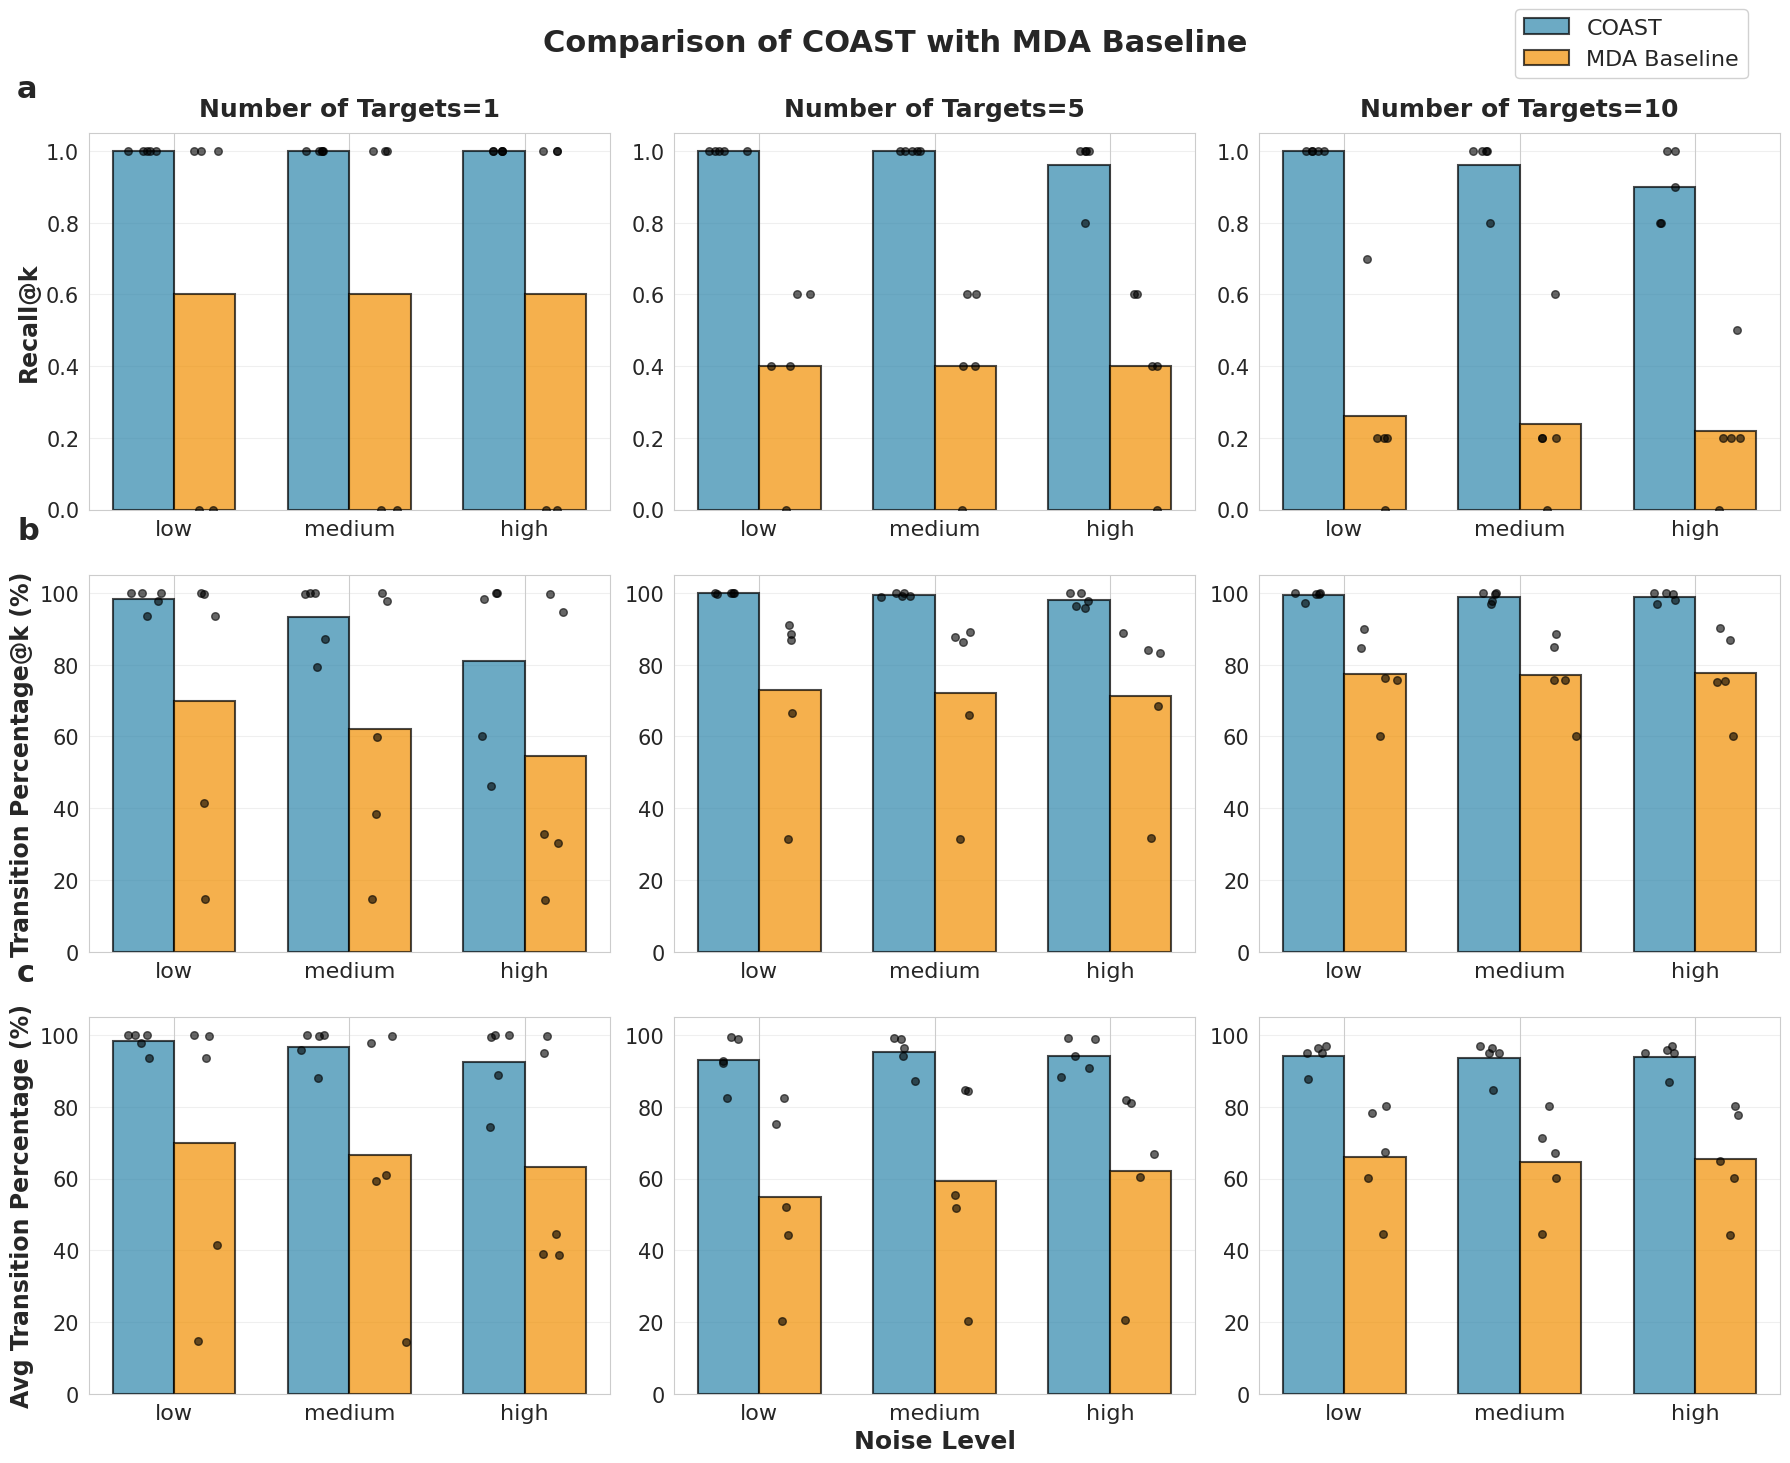


✓ Combined visualization completed


In [ ]:
# Combined plot: Visualization 1b + 2b + 4b (3 rows x 3 columns)
# Filter data for nnodes=100, prob=0.2
filtered_df = all_metrics_df[(all_metrics_df['nnodes'] == 100) & (all_metrics_df['prob'] == 0.2)].copy()
ntargets_vals = sorted(filtered_df['ntargets'].unique())
noise_vals = sorted(filtered_df['noise'].unique())

fig, axes = plt.subplots(3, 3, figsize=(18, 15))

# Row configs: (metric_ours, metric_de, ylabel, ylim, yticks, multiply_100)
row_configs = [
    ('recall_at_k', 'de_recall_at_k', 'Recall@k', (0, 1.05), None, False),
    ('best_solution_transprop', 'de_best_transprop', 'Transition Percentage@k (%)', (0, 105), np.arange(0, 101, 20), True),
    ('avg_transprop_our', 'avg_transprop_de', 'Avg Transition Percentage (%)', (0, 105), np.arange(0, 101, 20), True),
]

bar_width = 0.35
method_color_ours = '#2E86AB'
method_color_de = '#F18F01'

for row_idx, (metric_ours, metric_de, ylabel, ylim, yticks, mult100) in enumerate(row_configs):
    for col_idx, ntargets in enumerate(ntargets_vals):
        ax = axes[row_idx, col_idx]
        x_positions = np.arange(len(noise_vals))

        for metric, color, label_name, offset in [
            (metric_ours, method_color_ours, 'COAST', -bar_width / 2),
            (metric_de, method_color_de, 'MDA Baseline', bar_width / 2),
        ]:
            positions = x_positions + offset
            data_to_plot = []
            for noise in noise_vals:
                subset = filtered_df[(filtered_df['ntargets'] == ntargets) &
                                    (filtered_df['noise'] == noise)]
                values = subset[metric].values
                if mult100:
                    values = values * 100
                data_to_plot.append(values)

            means = [np.mean(vals) if len(vals) > 0 else 0 for vals in data_to_plot]
            ax.bar(positions, means, bar_width,
                   label=label_name if (row_idx == 0 and col_idx == 0) else None,
                   color=color, alpha=0.7,
                   edgecolor='black', linewidth=1.5)

            for i, (pos, vals) in enumerate(zip(positions, data_to_plot)):
                if len(vals) > 0:
                    jitter = np.random.normal(0, bar_width * 0.15, len(vals))
                    ax.scatter(pos + jitter, vals, color='black', s=30, alpha=0.6, zorder=3)

        ax.set_ylim(*ylim)
        if yticks is not None:
            ax.set_yticks(yticks)
        ax.set_xticks(x_positions)
        ax.set_xticklabels(['low', 'medium', 'high'], fontsize=16)
        ax.grid(True, alpha=0.3, axis='y')
        ax.tick_params(axis='y', labelsize=15)

        # X-axis label: only on bottom row, middle column
        if row_idx == 2 and col_idx == 1:
            ax.set_xlabel('Noise Level', fontsize=18, fontweight='bold')

        # Column subtitles: only on top row
        if row_idx == 0:
            ax.set_title(f'Number of Targets={ntargets}', fontsize=18, fontweight='bold', pad=12)

        # Y-axis labels: only on leftmost column
        if col_idx == 0:
            ax.set_ylabel(ylabel, fontsize=17, fontweight='bold')

plt.tight_layout(h_pad=3.0)

# Add legend at the upper right corner of the whole figure
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', fontsize=16, framealpha=0.9,
           bbox_to_anchor=(0.98, 0.98))

# Add title well above column subtitles
fig.subplots_adjust(top=0.89)
fig.suptitle('Comparison of COAST with MDA Baseline',
             fontsize=22, fontweight='bold', y=0.96)

# Add row labels (a, b, c) to the upper left corner of each row
row_labels = ['a', 'b', 'c']
for row_idx, label in enumerate(row_labels):
    ax = axes[row_idx, 0]
    pos = ax.get_position()
    fig.text(pos.x0 - 0.04, pos.y1 + 0.02, label,
             fontsize=22, fontweight='bold', ha='left', va='bottom')

plt.savefig('combined_comparison_by_noise.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Combined visualization completed")

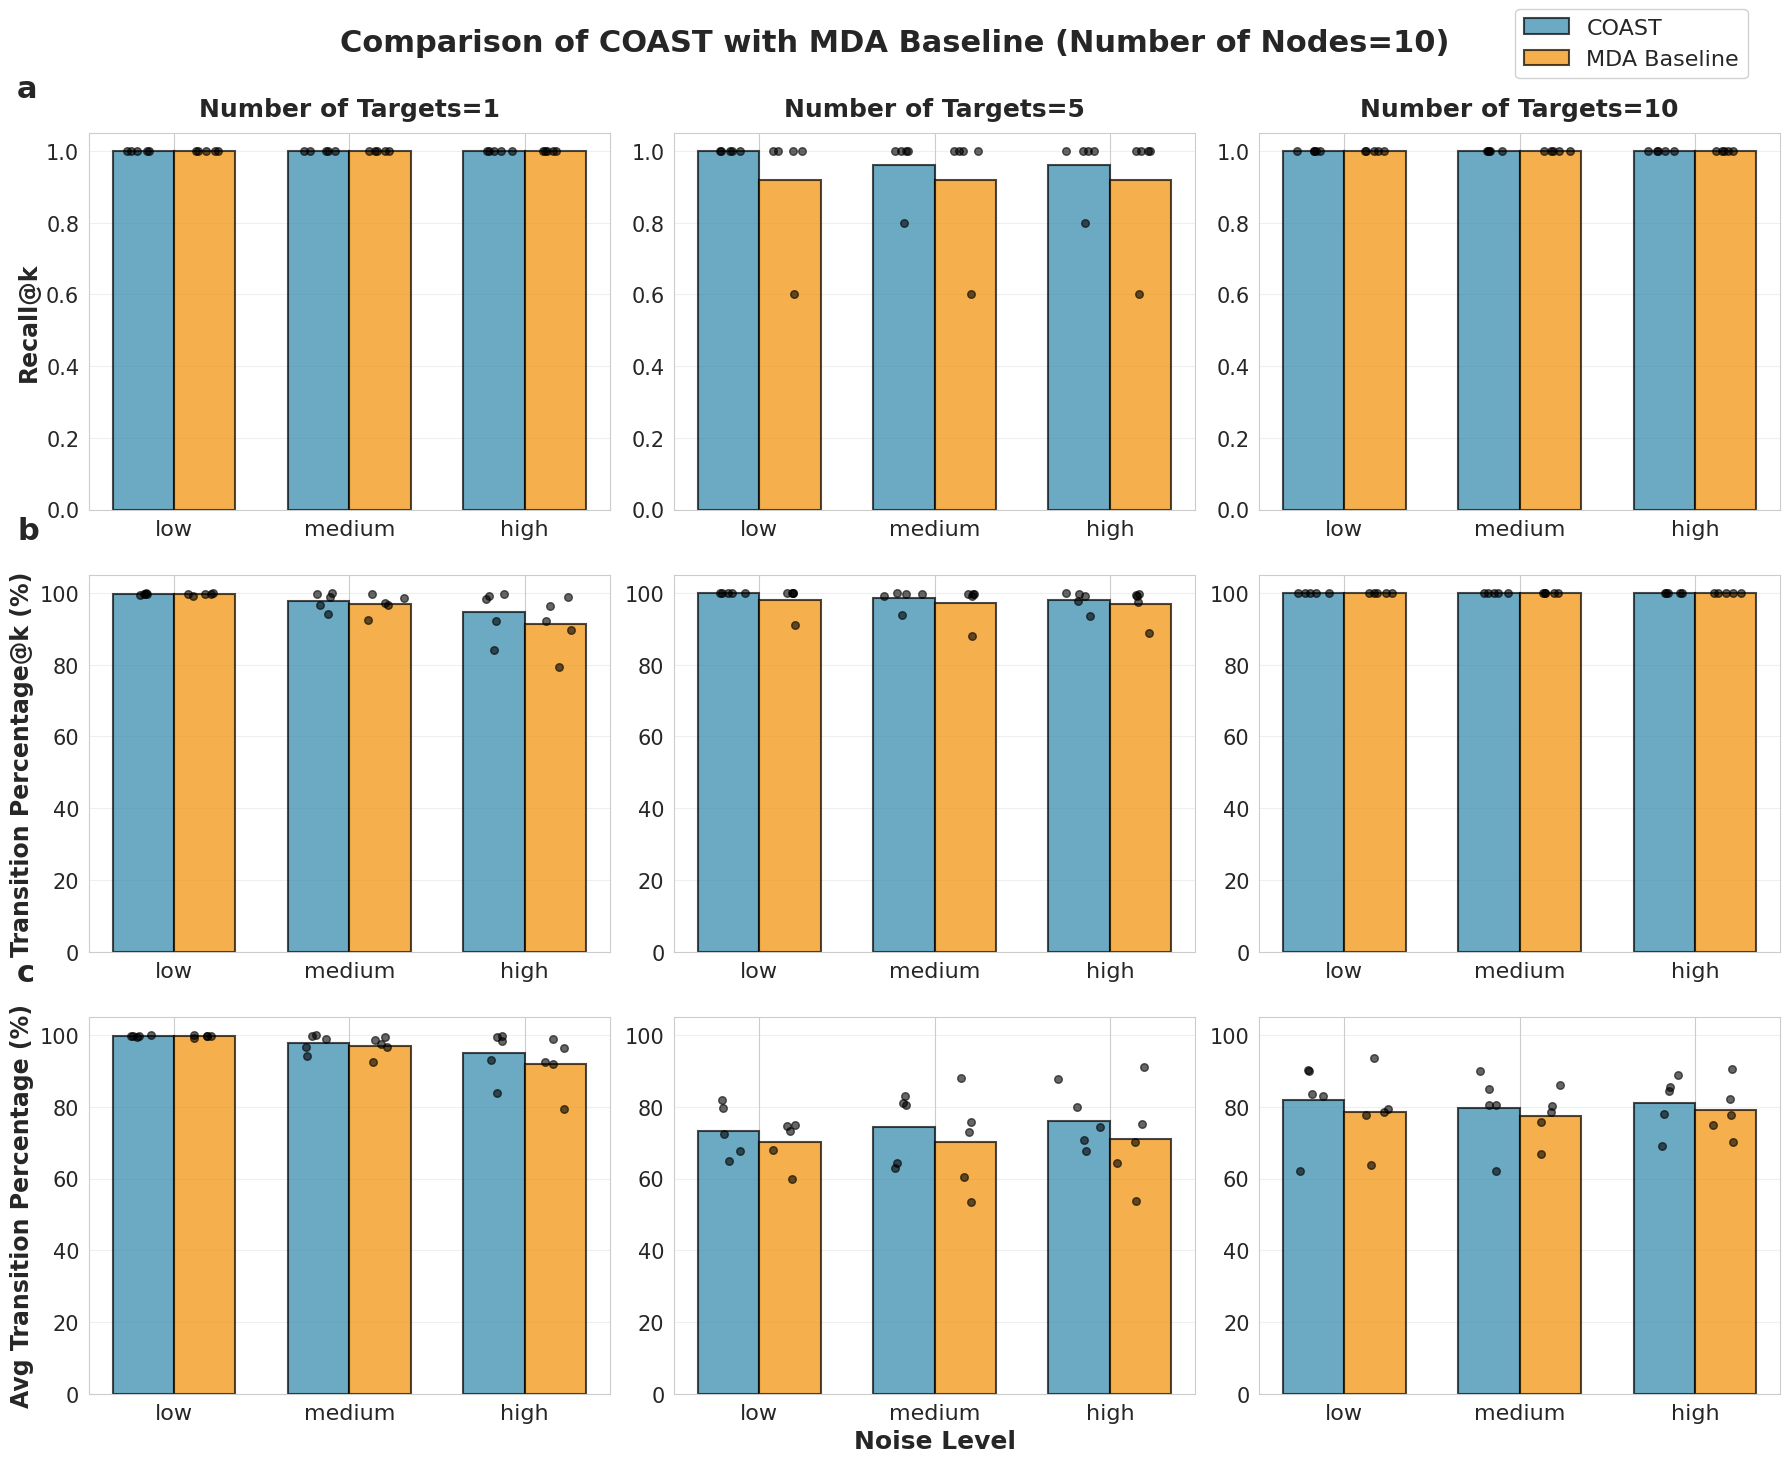


✓ Combined visualization (nnodes=10) completed


In [ ]:
# Combined plot for nnodes=10
filtered_df = all_metrics_df[(all_metrics_df['nnodes'] == 10) & (all_metrics_df['prob'] == 0.2)].copy()
ntargets_vals = sorted(filtered_df['ntargets'].unique())
noise_vals = sorted(filtered_df['noise'].unique())

fig, axes = plt.subplots(3, 3, figsize=(18, 15))

row_configs = [
    ('recall_at_k', 'de_recall_at_k', 'Recall@k', (0, 1.05), None, False),
    ('best_solution_transprop', 'de_best_transprop', 'Transition Percentage@k (%)', (0, 105), np.arange(0, 101, 20), True),
    ('avg_transprop_our', 'avg_transprop_de', 'Avg Transition Percentage (%)', (0, 105), np.arange(0, 101, 20), True),
]

bar_width = 0.35
method_color_ours = '#2E86AB'
method_color_de = '#F18F01'

for row_idx, (metric_ours, metric_de, ylabel, ylim, yticks, mult100) in enumerate(row_configs):
    for col_idx, ntargets in enumerate(ntargets_vals):
        ax = axes[row_idx, col_idx]
        x_positions = np.arange(len(noise_vals))

        for metric, color, label_name, offset in [
            (metric_ours, method_color_ours, 'COAST', -bar_width / 2),
            (metric_de, method_color_de, 'MDA Baseline', bar_width / 2),
        ]:
            positions = x_positions + offset
            data_to_plot = []
            for noise in noise_vals:
                subset = filtered_df[(filtered_df['ntargets'] == ntargets) &
                                    (filtered_df['noise'] == noise)]
                values = subset[metric].values
                if mult100:
                    values = values * 100
                data_to_plot.append(values)

            means = [np.mean(vals) if len(vals) > 0 else 0 for vals in data_to_plot]
            ax.bar(positions, means, bar_width,
                   label=label_name if (row_idx == 0 and col_idx == 0) else None,
                   color=color, alpha=0.7,
                   edgecolor='black', linewidth=1.5)

            for i, (pos, vals) in enumerate(zip(positions, data_to_plot)):
                if len(vals) > 0:
                    jitter = np.random.normal(0, bar_width * 0.15, len(vals))
                    ax.scatter(pos + jitter, vals, color='black', s=30, alpha=0.6, zorder=3)

        ax.set_ylim(*ylim)
        if yticks is not None:
            ax.set_yticks(yticks)
        ax.set_xticks(x_positions)
        ax.set_xticklabels(['low', 'medium', 'high'], fontsize=16)
        ax.grid(True, alpha=0.3, axis='y')
        ax.tick_params(axis='y', labelsize=15)

        if row_idx == 2 and col_idx == 1:
            ax.set_xlabel('Noise Level', fontsize=18, fontweight='bold')
        if row_idx == 0:
            ax.set_title(f'Number of Targets={ntargets}', fontsize=18, fontweight='bold', pad=12)
        if col_idx == 0:
            ax.set_ylabel(ylabel, fontsize=17, fontweight='bold')

plt.tight_layout(h_pad=3.0)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', fontsize=16, framealpha=0.9,
           bbox_to_anchor=(0.98, 0.98))

fig.subplots_adjust(top=0.89)
fig.suptitle('Comparison of COAST with MDA Baseline (Number of Nodes=10)',
             fontsize=22, fontweight='bold', y=0.96)

row_labels = ['a', 'b', 'c']
for row_idx, label in enumerate(row_labels):
    ax = axes[row_idx, 0]
    pos = ax.get_position()
    fig.text(pos.x0 - 0.04, pos.y1 + 0.02, label,
             fontsize=22, fontweight='bold', ha='left', va='bottom')

plt.savefig('combined_comparison_by_noise_nnodes10.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Combined visualization (nnodes=10) completed")

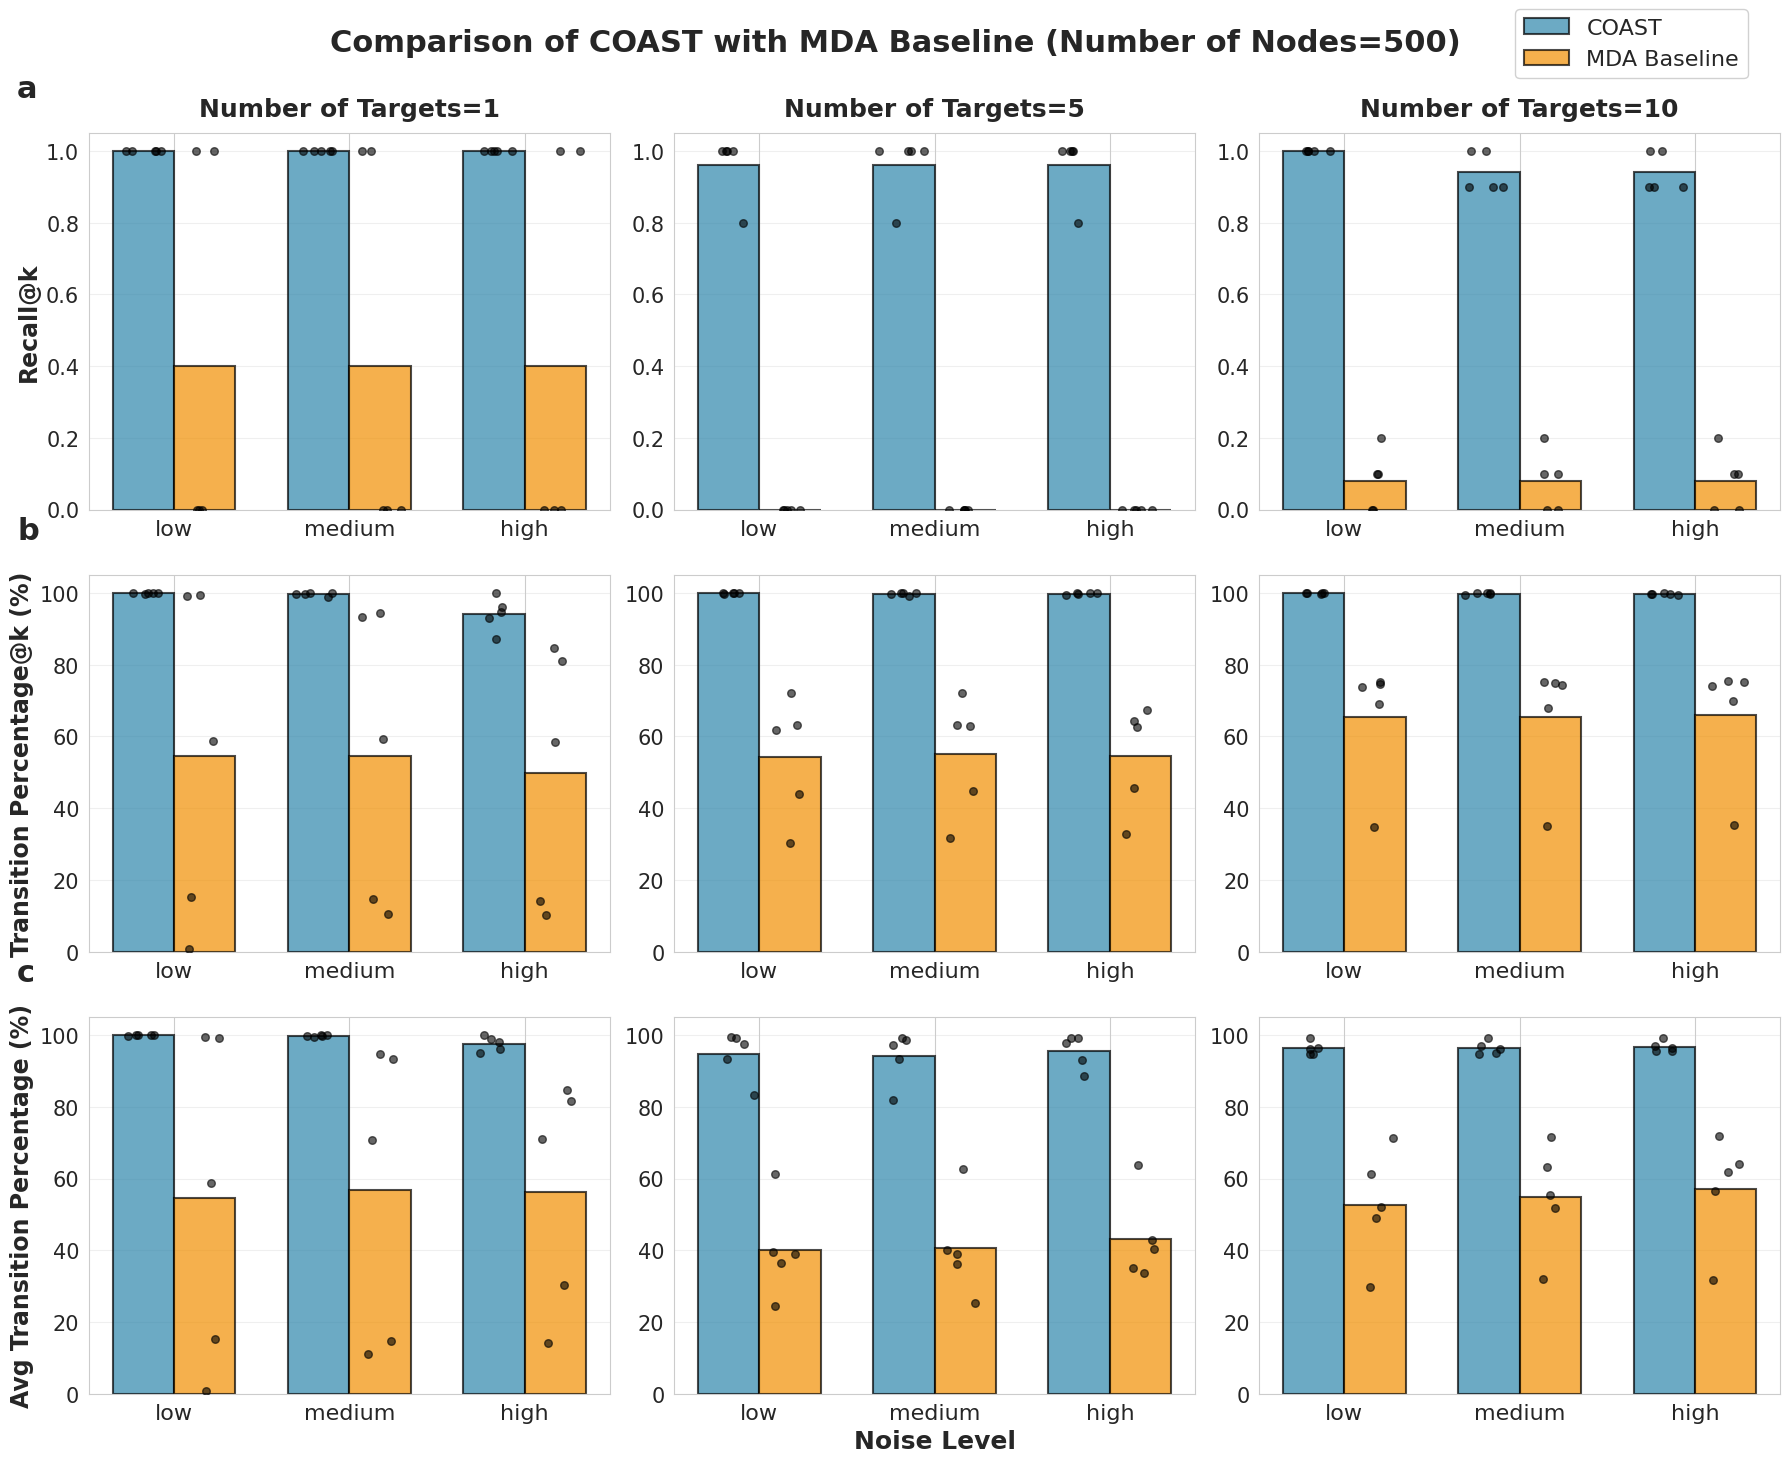


✓ Combined visualization (nnodes=500) completed


In [ ]:
# Combined plot for nnodes=500
filtered_df = all_metrics_df[(all_metrics_df['nnodes'] == 500) & (all_metrics_df['prob'] == 0.2)].copy()
ntargets_vals = sorted(filtered_df['ntargets'].unique())
noise_vals = sorted(filtered_df['noise'].unique())

fig, axes = plt.subplots(3, 3, figsize=(18, 15))

row_configs = [
    ('recall_at_k', 'de_recall_at_k', 'Recall@k', (0, 1.05), None, False),
    ('best_solution_transprop', 'de_best_transprop', 'Transition Percentage@k (%)', (0, 105), np.arange(0, 101, 20), True),
    ('avg_transprop_our', 'avg_transprop_de', 'Avg Transition Percentage (%)', (0, 105), np.arange(0, 101, 20), True),
]

bar_width = 0.35
method_color_ours = '#2E86AB'
method_color_de = '#F18F01'

for row_idx, (metric_ours, metric_de, ylabel, ylim, yticks, mult100) in enumerate(row_configs):
    for col_idx, ntargets in enumerate(ntargets_vals):
        ax = axes[row_idx, col_idx]
        x_positions = np.arange(len(noise_vals))

        for metric, color, label_name, offset in [
            (metric_ours, method_color_ours, 'COAST', -bar_width / 2),
            (metric_de, method_color_de, 'MDA Baseline', bar_width / 2),
        ]:
            positions = x_positions + offset
            data_to_plot = []
            for noise in noise_vals:
                subset = filtered_df[(filtered_df['ntargets'] == ntargets) &
                                    (filtered_df['noise'] == noise)]
                values = subset[metric].values
                if mult100:
                    values = values * 100
                data_to_plot.append(values)

            means = [np.mean(vals) if len(vals) > 0 else 0 for vals in data_to_plot]
            ax.bar(positions, means, bar_width,
                   label=label_name if (row_idx == 0 and col_idx == 0) else None,
                   color=color, alpha=0.7,
                   edgecolor='black', linewidth=1.5)

            for i, (pos, vals) in enumerate(zip(positions, data_to_plot)):
                if len(vals) > 0:
                    jitter = np.random.normal(0, bar_width * 0.15, len(vals))
                    ax.scatter(pos + jitter, vals, color='black', s=30, alpha=0.6, zorder=3)

        ax.set_ylim(*ylim)
        if yticks is not None:
            ax.set_yticks(yticks)
        ax.set_xticks(x_positions)
        ax.set_xticklabels(['low', 'medium', 'high'], fontsize=16)
        ax.grid(True, alpha=0.3, axis='y')
        ax.tick_params(axis='y', labelsize=15)

        if row_idx == 2 and col_idx == 1:
            ax.set_xlabel('Noise Level', fontsize=18, fontweight='bold')
        if row_idx == 0:
            ax.set_title(f'Number of Targets={ntargets}', fontsize=18, fontweight='bold', pad=12)
        if col_idx == 0:
            ax.set_ylabel(ylabel, fontsize=17, fontweight='bold')

plt.tight_layout(h_pad=3.0)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', fontsize=16, framealpha=0.9,
           bbox_to_anchor=(0.98, 0.98))

fig.subplots_adjust(top=0.89)
fig.suptitle('Comparison of COAST with MDA Baseline (Number of Nodes=500)',
             fontsize=22, fontweight='bold', y=0.96)

row_labels = ['a', 'b', 'c']
for row_idx, label in enumerate(row_labels):
    ax = axes[row_idx, 0]
    pos = ax.get_position()
    fig.text(pos.x0 - 0.04, pos.y1 + 0.02, label,
             fontsize=22, fontweight='bold', ha='left', va='bottom')

plt.savefig('combined_comparison_by_noise_nnodes500.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Combined visualization (nnodes=500) completed")